# 04 - What drives churn risk (SHAP)

**What is explained.** The champion in the MLflow registry (`bank-churn-model@champion`) is a calibrated ensemble: five XGBoost models, one per cross-validation fold,
each followed by its own isotonic calibrator. SHAP (`TreeExplainer`) is computed on each of the five XGBoost models for the test customers and averaged.

**Why it is fine to explain the trees and not the calibrated probability.** Isotonic calibration is a monotonic transformation: it changes the probability values but not the ordering of customers.
Each fold model's calibrator preserves that model's ranking, and the champion averages five of them, so its ranking matches the averaged tree scores almost exactly
(Spearman correlation printed below). The drivers of the tree score are therefore the drivers of who ranks as high risk. Probabilities themselves (used in Stage 5) come from the calibrated model.

**Units.** SHAP values are in log-odds of churn: positive pushes a customer toward churning, negative away from it. For every customer, the base value plus all SHAP values equals the model's log-odds (checked below).

**Levers.** Each feature is tagged *Customer*, *Product* or *Engagement*, following the Stage 2 split. Balance-based features (`Balance`, `zero_balance`, `balance_to_salary`) sit under *Product*,
as in the EDA. `active_x_products` sits under *Engagement* because it is an activity flag times product count. `Tenure` is *Engagement*.

**Read with care.** SHAP describes what the model relies on, not what causes churn. Correlated features share credit (for example `Age` and `is_senior`, or `NumOfProducts` and `active_x_products`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from matplotlib.patches import Patch
from scipy.stats import spearmanr

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from src.models.drivers import LEVER_OF, champion_shap
from src.models.registry import load_champion, load_test_features

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
LEVER_COLORS = {"Customer": "#2a78d6", "Product": "#eb6834", "Engagement": "#1baf7a"}

X, y = load_test_features()
champion = load_champion()
sv, base, margin = champion_shap(champion, X)
risk = champion.predict_proba(X)[:, 1]

print(f"{len(X):,} test customers, {X.shape[1]} features")
print(f"additivity: max |SHAP sum + base - model log-odds| = {np.abs(sv.sum(axis=1) + base - margin).max():.2e}")
print(f"ranking agreement: Spearman(averaged tree log-odds, calibrated champion probability) = {spearmanr(margin, risk).statistic:.4f}")

2,000 test customers, 18 features
additivity: max |SHAP sum + base - model log-odds| = 1.67e-06
ranking agreement: Spearman(averaged tree log-odds, calibrated champion probability) = 0.9981


## Global importance
Mean absolute SHAP value per feature (average size of its push on a customer's log-odds), coloured by lever.

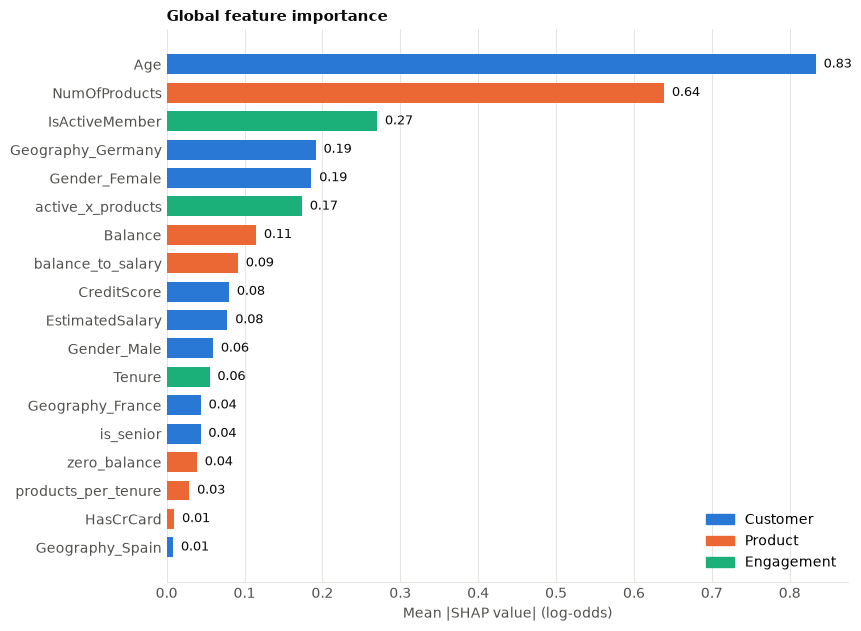

Importance summed by lever (a feature's credit can be split across correlated features, so read this loosely):


,mean_abs_shap_total,share_pct
Customer,1.52,51.740002
Product,0.92,31.320000
Engagement,0.50,16.940001


In [2]:
imp = pd.Series(np.abs(sv).mean(axis=0), index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 6.2), constrained_layout=True)
ax.barh(imp.index, imp.values, color=[LEVER_COLORS[LEVER_OF[f]] for f in imp.index], height=0.7)
for i, v in enumerate(imp.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", color=INK, fontsize=9)
ax.set_xlabel("Mean |SHAP value| (log-odds)", color=MUTED)
ax.set_title("Global feature importance", loc="left", color=INK, fontsize=11, fontweight="bold")
ax.legend(handles=[Patch(color=c, label=l) for l, c in LEVER_COLORS.items()], frameon=False, loc="lower right")
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=MUTED, length=0)
plt.show()

by_lever = pd.DataFrame({"mean_abs_shap_total": imp.groupby(imp.index.map(LEVER_OF)).sum()})
by_lever["share_pct"] = 100 * by_lever["mean_abs_shap_total"] / by_lever["mean_abs_shap_total"].sum()
print("Importance summed by lever (a feature's credit can be split across correlated features, so read this loosely):")
display(by_lever.sort_values("share_pct", ascending=False).round(2))

## Beeswarm
Each dot is one test customer. Position is the push on churn log-odds; colour is the feature value (red = high, blue = low). Lever shown in brackets.

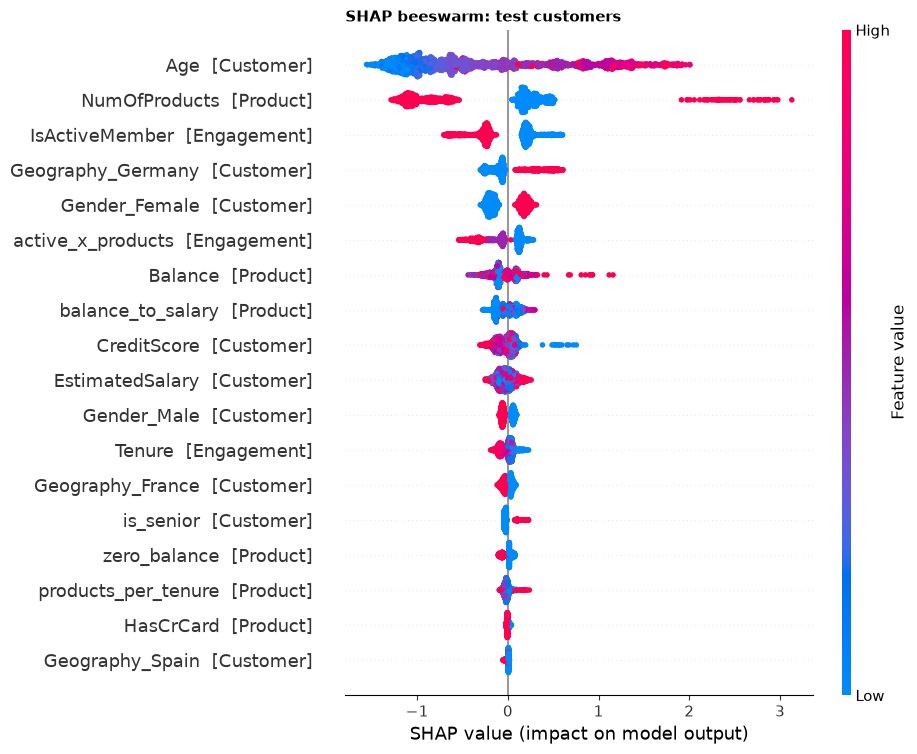

In [3]:
shap.summary_plot(sv, X, feature_names=[f"{c}  [{LEVER_OF[c]}]" for c in X.columns], max_display=18, show=False, plot_size=(9.5, 7.5))
plt.title("SHAP beeswarm: test customers", loc="left", fontsize=11, fontweight="bold")
plt.show()

## Dependence plots
How the push on churn log-odds changes with the feature value. Dot colour shows the feature that interacts most with it.

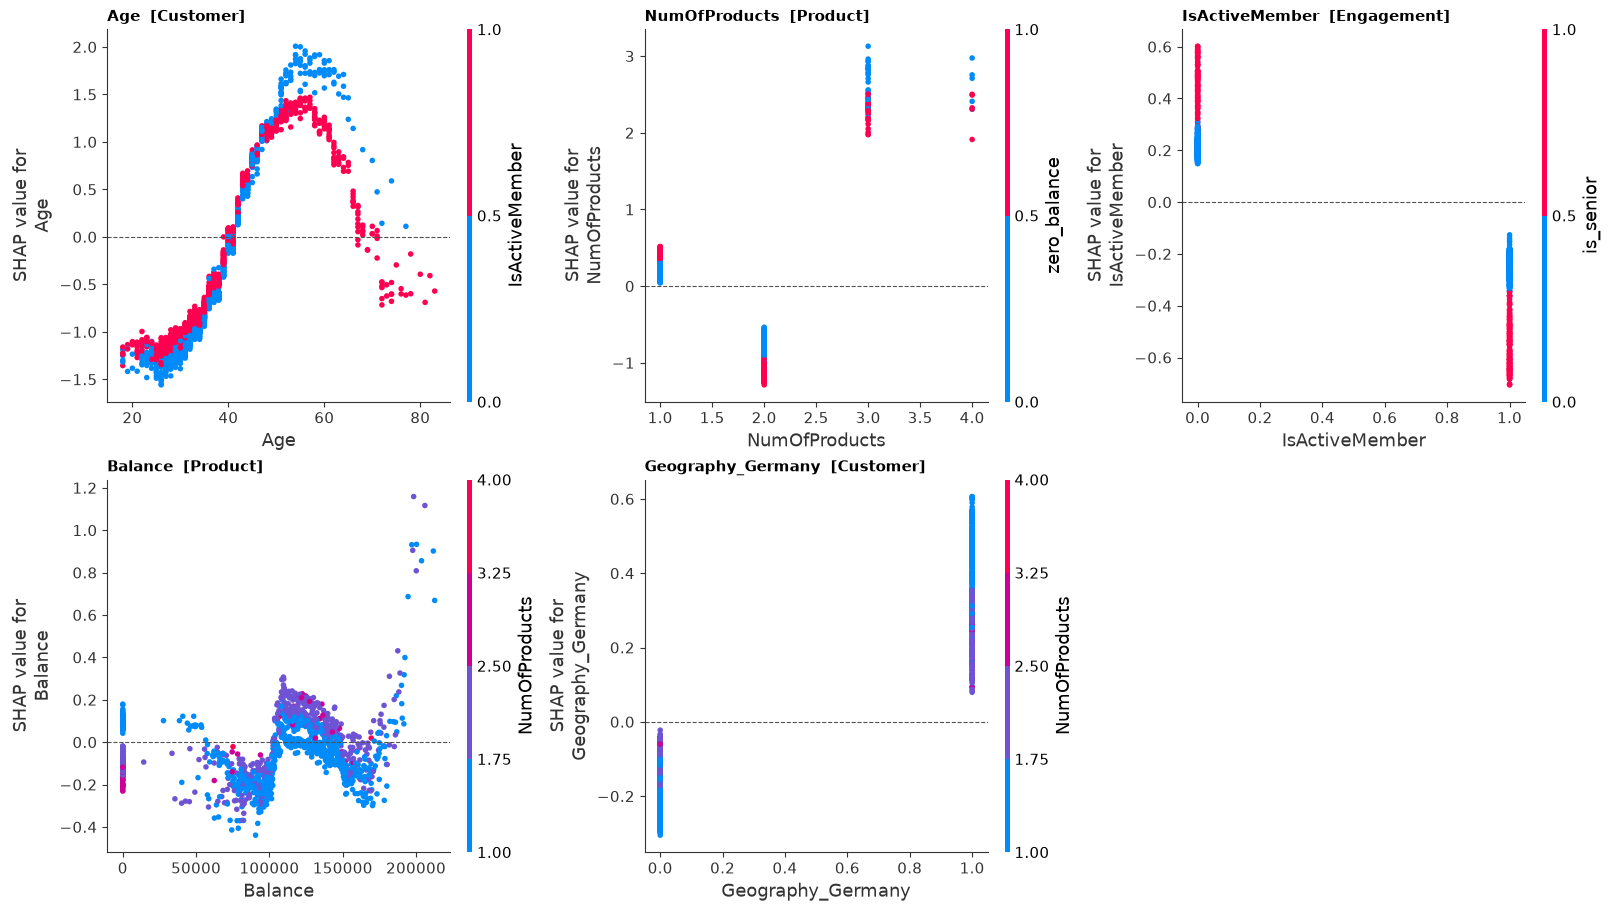

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
for ax, feature in zip(axes.ravel(), ["Age", "NumOfProducts", "IsActiveMember", "Balance", "Geography_Germany"]):
    shap.dependence_plot(feature, sv, X, ax=ax, show=False)
    ax.set_title(f"{feature}  [{LEVER_OF[feature]}]", loc="left", fontsize=11, fontweight="bold")
    ax.axhline(0, color=MUTED, lw=0.8, ls="--")
axes[1, 2].axis("off")
plt.show()

## Three high-risk customers
Chosen to show different routes to a high score: the highest-risk test customer overall, and the highest-risk customers among those holding 1 product and 2 products (the two largest product groups).
Each waterfall starts at the average log-odds and adds each feature's push, ending at that customer's log-odds. Ages and balances are the customer's own values.

,Age,NumOfProducts,IsActiveMember,Balance,Tenure,CreditScore,Geography,risk,churned_actual
Highest risk overall,52,3,0,116497.31,5,521,Germany,1.000,1
"Highest risk, 1 product",58,1,0,0.00,4,599,France,0.987,1
"Highest risk, 2 products",61,2,0,129855.72,4,785,Spain,0.901,1


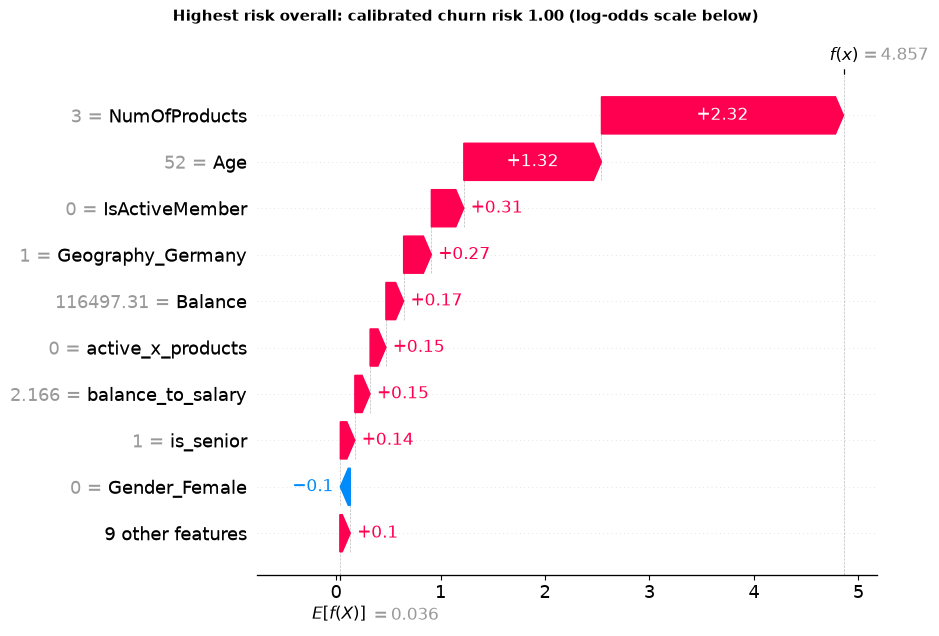

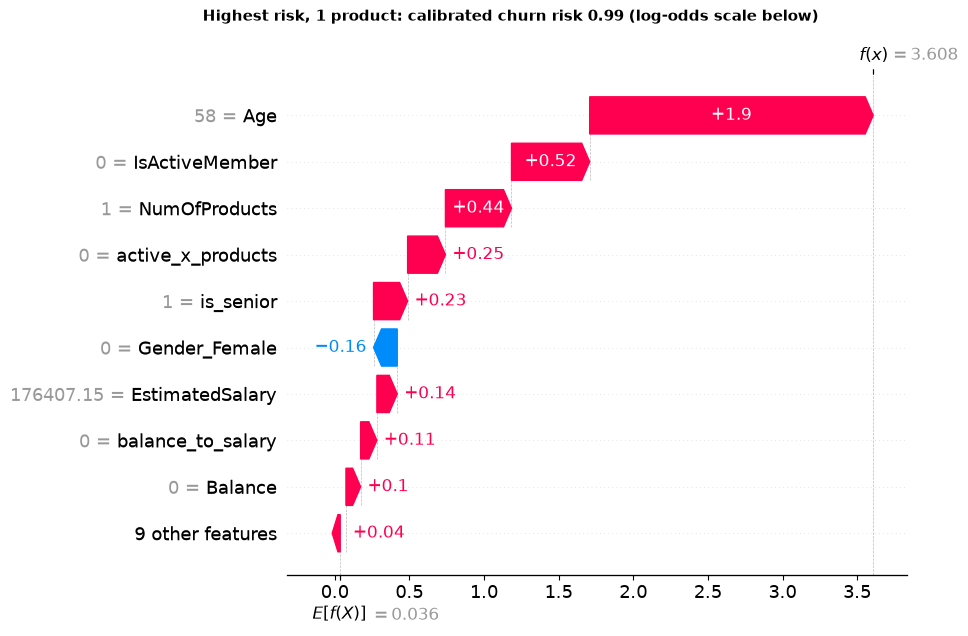

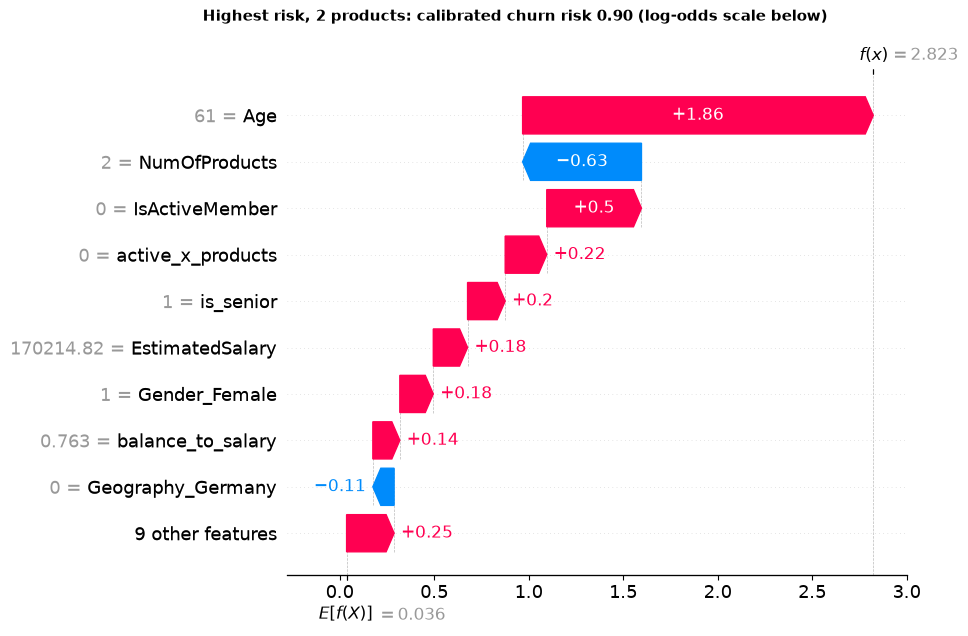

In [5]:
geo = X[["Geography_France", "Geography_Germany", "Geography_Spain"]].idxmax(axis=1).str.replace("Geography_", "")


def top(mask):
    return int(np.argmax(np.where(mask, risk, -1)))


picks = {"Highest risk overall": top(np.ones(len(X), dtype=bool)),
         "Highest risk, 1 product": top((X["NumOfProducts"] == 1).to_numpy()),
         "Highest risk, 2 products": top((X["NumOfProducts"] == 2).to_numpy())}
idx = list(picks.values())
cols = ["Age", "NumOfProducts", "IsActiveMember", "Balance", "Tenure", "CreditScore"]
examples = X.loc[idx, cols].assign(Geography=geo.iloc[idx].values, risk=risk[idx], churned_actual=y[idx])
examples.index = list(picks)
display(examples.round(3))

for label, i in picks.items():
    exp = shap.Explanation(values=sv[i], base_values=base, data=X.iloc[i].to_numpy(), feature_names=list(X.columns))
    shap.plots.waterfall(exp, max_display=10, show=False)
    plt.gcf().suptitle(f"{label}: calibrated churn risk {risk[i]:.2f} (log-odds scale below)", x=0.02, ha="left", fontsize=11, fontweight="bold")
    plt.show()

## Does the model need Gender? An ablation
Gender is a sensitive attribute, and the model uses it (the Female push is about +0.2 log-odds). To check how much it adds, the champion setup was retrained **without** `Gender_Female` and `Gender_Male`:
same train/test split, same XGBoost search space and seed, same calibration choice (`python -m src.models.ablation`). It is logged to MLflow as its own run; the registered champion is unchanged.
The table compares the two models on the same test customers. The difference comes with a 95% confidence interval from a paired bootstrap (1,000 resamples, both models scored on the same resampled customers).

In [6]:
import mlflow

mlflow.set_tracking_uri(f"sqlite:///{(root / 'mlflow.db').as_posix()}")
runs = mlflow.search_runs(experiment_names=["bank-churn"])
by_name = runs.set_index("tags.mlflow.runName")
champ_run, abl_run, parent_run = by_name.loc["xgboost_calibrated"], by_name.loc["xgboost_calibrated_no_gender"], by_name.loc["stage5-gender-ablation"]
rows = []
for m, label in (("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"), ("brier", "Brier (lower is better)")):
    rows.append({"metric": label, "champion (with Gender)": champ_run[f"metrics.test_{m}"], "without Gender": abl_run[f"metrics.test_{m}"],
                 "difference": parent_run[f"metrics.paired_diff_{m}_mean"], "95% CI low": parent_run[f"metrics.paired_diff_{m}_ci_low"],
                 "95% CI high": parent_run[f"metrics.paired_diff_{m}_ci_high"]})
display(pd.DataFrame(rows).set_index("metric").round(4))
print(f"Cross-validation PR-AUC on train: champion {champ_run['metrics.cv_pr_auc_mean']:.4f}, without Gender {abl_run['metrics.cv_pr_auc_mean']:.4f}")

,champion (with Gender),without Gender,difference,95% CI low,95% CI high
metric,,,,,
ROC-AUC,0.8646,0.8647,0.0002,-0.0050,0.0059
PR-AUC,0.6949,0.6871,-0.0076,-0.0163,0.0009
Brier (lower is better),0.1034,0.1041,0.0007,-0.0008,0.0021


Cross-validation PR-AUC on train: champion 0.7062, without Gender 0.7034


**Result: dropping Gender costs essentially nothing measurable.**
- ROC-AUC is unchanged (difference +0.0002, 95% CI -0.0050 to +0.0059) and so is the Brier score (+0.0007, CI -0.0008 to +0.0021).
- PR-AUC is 0.0076 lower without Gender (0.6871 against 0.6949). The 95% interval, -0.0163 to +0.0009, only just includes zero: a small loss of up to about 0.016 is possible, but it cannot be told apart from noise on this test set.
- Cross-validation on the training data agrees: PR-AUC 0.7034 without Gender against 0.7062 with it, well inside one fold standard deviation (about 0.016).

**What it means.** The model ranks churn risk about as well without Gender, so leaving it out of a production model, and out of any targeting rule, looks like a low-cost choice that avoids relying on a sensitive attribute.

**Caveats.** Removing the column does not make the model blind to gender: correlated features (products, balance, geography) can act as proxies. The ablation's search also settled on somewhat different tuned settings, so part of any difference is search noise rather than the missing feature, and this is one retraining on one split.
The registered champion (v1) is unchanged; whether to ship a no-gender model is a separate decision.

## Driver summary in plain English

**What the model leans on, in order.** Age (mean |SHAP| 0.83), number of products (0.64), active membership (0.27), Germany (0.19), gender (0.19), then the active-times-products interaction (0.17) and balance (0.12).
By lever, roughly half the importance sits with customer attributes, about a third with product features and about a sixth with engagement (read these shares loosely: correlated features split the credit).

### Actionable levers: things the bank can influence
- **Number of products (Product).** The strongest lever. Holding 2 products lowers risk (push of about -0.5 to -1.3 log-odds), 1 product raises it slightly (+0.1 to +0.5), and 3 or 4 products raise it sharply (+2 to +3).
  The 3-4 product group is small (about 330 customers in the data), but the pattern is consistent with the EDA. This is an association: it says where churn concentrates, not that moving a customer from 1 to 2 products would keep them. That needs a test.
- **Active membership (Engagement).** Inactive members are pushed toward churn (+0.2 to +0.6) and active members away from it (-0.1 to -0.7), a swing of roughly 0.7 to 1.0 log-odds, with a further push from the `active_x_products` interaction.
  Activity also changes how much age matters: the age effect peaks lower for active members (about +1.3 at age 55, against about +1.9 for inactive members). Re-engaging inactive customers is the most practical lever here.

### Targeting variables: who to look at, not something to change
- **Age (Customer).** The biggest single driver and clearly non-linear: risk climbs from about -1.2 in the early 20s to a peak around 50-60 (+1.5 to +2.0) and eases again after about 65.
  Age tells you which customers to prioritise; it cannot be acted on.
- **Geography (Customer).** Being in Germany pushes risk up (+0.1 to +0.6), France and Spain push it down slightly. Use it to decide where to investigate (pricing, competition, service), not as a lever.
- **Gender, credit score, salary.** Women are pushed up about 0.2 and men down about 0.2; credit score and salary matter little. Gender and age are sensitive attributes in many settings; whether they may be used to decide who receives an offer is a compliance question, and they are safer as monitoring variables than as targeting rules.
  The ablation above shows the model loses nothing measurable if Gender is dropped.
- **Balance and tenure.** Weak and uneven. Balance shows a modest rise through 100-150 thousand units and a large push for the few customers above about 180 thousand, which is based on very few customers and should be treated as tentative.

### The three example customers
- *Highest risk overall* (Germany, age 52, 3 products, inactive): every signal points the same way, risk about 1.00.
- *Highest risk with 1 product* (France, age 58, inactive, zero balance): age adds +1.9, inactivity +0.52 and holding only 1 product +0.44; risk 0.99.
- *Highest risk with 2 products* (Spain, age 61, inactive): holding 2 products is protective (-0.63) but age (+1.86) and inactivity (+0.50) outweigh it; risk 0.90.
All three actually churned, which fits the model, but three hand-picked customers are illustrations, not evidence.

### Caveats
SHAP shows what the model relies on, not what causes churn. Correlated features (age and `is_senior`, products and `active_x_products`) share credit, so individual numbers are approximate.
Everything here is from 2,000 test customers and one fitted model; the shapes (age peak, products pattern, activity gap) match the Stage 2 EDA, which is reassuring, but the exact values should not be over-read.